# RDKit Tutorial With Google Colab 
###Prof. Victor S. Batista 
**CHEM 584: Introduction to Machine Learning and Quantum Computing**

##Introduction

This tutorial shows how to use RDKit to visualize molecules from smiles strings. [RDKit](https://www.rdkit.org/) is a cheminformatics toolkit with bindings for Python. It is [extensively documented](https://www.rdkit.org/docs/) with [pedagogical examples](https://www.rdkit.org/docs/Cookbook.html) showing it is [highly functional](https://www.rdkit.org/docs/Cookbook.html). Furthermore, it is available from [multiple open source projects](https://www.rdkit.org/docs/Overview.html#usage-by-other-open-source-projects), and widely-used in machine learning applications.

To install RDKit with Google Colab:

In [ ]:
!pip install py3Dmol
!wget -c https://repo.continuum.io/miniconda/Miniconda3-py37_4.8.3-Linux-x86_64.sh
!chmod +x Miniconda3-py37_4.8.3-Linux-x86_64.sh
!time bash ./Miniconda3-py37_4.8.3-Linux-x86_64.sh -b -f -p /usr/local
!time conda install -q -y -c conda-forge rdkit=2020.03.5


--2021-09-12 02:24:41--  https://repo.continuum.io/miniconda/Miniconda3-py37_4.8.3-Linux-x86_64.sh
Resolving repo.continuum.io (repo.continuum.io)... 104.18.200.79, 104.18.201.79, 2606:4700::6812:c84f, ...
Connecting to repo.continuum.io (repo.continuum.io)|104.18.200.79|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://repo.anaconda.com/miniconda/Miniconda3-py37_4.8.3-Linux-x86_64.sh [following]
--2021-09-12 02:24:41--  https://repo.anaconda.com/miniconda/Miniconda3-py37_4.8.3-Linux-x86_64.sh
Resolving repo.anaconda.com (repo.anaconda.com)... 104.16.130.3, 104.16.131.3, 2606:4700::6810:8203, ...
Connecting to repo.anaconda.com (repo.anaconda.com)|104.16.130.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 88867207 (85M) [application/x-sh]
Saving to: ‘Miniconda3-py37_4.8.3-Linux-x86_64.sh’

Miniconda3-py37_4.8 100%[===================>]  84.75M   122MB/s    in 0.7s    

2021-09-12 02:24:42 (122 MB/s) - ‘Minicon

In [ ]:
#!pip install kora -q
#import kora.install.rdkit

In [ ]:
import sys
sys.path.append('/usr/local/lib/python3.7/site-packages/')
import rdkit
from rdkit import Chem
from rdkit.Chem import Descriptors, Descriptors3D, DetectBondStereoChemistry
from rdkit.Chem import AllChem, Draw, Crippen, Lipinski,inchi
from rdkit.Chem.Draw.MolDrawing import MolDrawing, DrawingOptions
from rdkit.Chem.Draw import IPythonConsole
import numpy as np
import random
import pickle
import time

In [ ]:
import torch
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm

In [ ]:
DrawingOptions.bondLineWidth=1.8

To create a molecule object from a [SMILES](https://en.wikipedia.org/wiki/Simplified_molecular-input_line-entry_system) string:

In [ ]:
#m = Chem.MolFromSmiles('c1nccc2n1ccc2')
m = Chem.MolFromSmiles('C=CC1=C(N2C(C(C2=O)NC(=O)/C(=N/OCC(=O)[O-])/c3csc(n3)N)SC1)C(=O)[O-]')

Display the molecule that you have just created

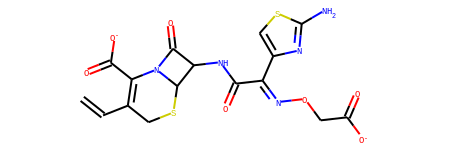

In [ ]:
m

To visualize the molecule in 3D



You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

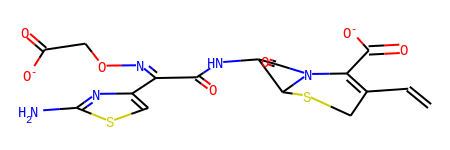

In [ ]:
rdkit.Chem.Draw.IPythonConsole.ipython_3d = True 

# This function make it shorter for view  in 3D
def view3D(molecule):
  AllChem.EmbedMolecule(molecule)
  return molecule

view3D(m)

Query number of heavy atoms

In [ ]:
m.GetNumAtoms()

30

Text representation

In [ ]:
from rdkit.Chem import Descriptors
Descriptors.MolLogP(m)

-3.2141999999999973

In [ ]:
print(Chem.MolToMolBlock(m))


     RDKit          3D

 30 32  0  0  0  0  0  0  0  0999 V2000
    7.5831   -1.1900   -0.8116 C   0  0  0  0  0  0  0  0  0  0  0  0
    6.8194   -0.5681    0.0421 C   0  0  0  0  0  0  0  0  0  0  0  0
    5.3426   -0.6719    0.0522 C   0  0  0  0  0  0  0  0  0  0  0  0
    4.6240   -0.0237    0.9354 C   0  0  0  0  0  0  0  0  0  0  0  0
    3.2370   -0.0436    1.0409 N   0  0  0  0  0  0  0  0  0  0  0  0
    2.3233   -0.6940    0.0832 C   0  0  0  0  0  0  0  0  0  0  0  0
    1.4617    0.4835    0.3169 C   0  0  0  0  0  0  0  0  0  0  0  0
    2.0601    0.3160    1.7055 C   0  0  0  0  0  0  0  0  0  0  0  0
    1.6871    0.4388    2.8919 O   0  0  0  0  0  0  0  0  0  0  0  0
    0.0533    0.3767    0.3042 N   0  0  0  0  0  0  0  0  0  0  0  0
   -0.7520   -0.1604   -0.7292 C   0  0  0  0  0  0  0  0  0  0  0  0
   -0.1695   -0.5965   -1.7466 O   0  0  0  0  0  0  0  0  0  0  0  0
   -2.2218   -0.1875   -0.5783 C   0  0  0  0  0  0  0  0  0  0  0  0
   -2.7829    0.2716    0

In [ ]:
DrawingOptions.includeAtomNumbers=True

You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

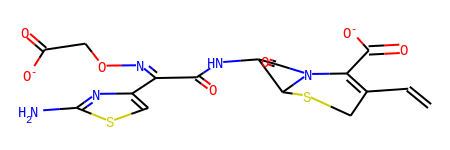

In [ ]:
m

Add hydrogens

You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

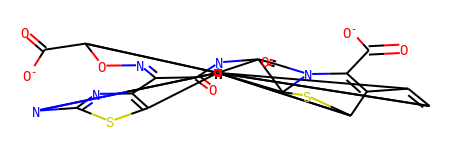

In [ ]:
m = AllChem.AddHs(m)
m

Generate 10 valid Smiles strings for the same molecule

[H]C(=C(C1=C(C(=O)[O-])N2C(C(N(C(/C(c3nc(N([H])[H])sc3[H])=N/OC(C(=O)[O-])([H])[H])=O)[H])([H])C2(SC1([H])[H])[H])=O)[H])[H]
N(\OC(C([O-])=O)([H])[H])=C(\c1c([H])sc(n1)N([H])[H])C(=O)N([H])C1([H])C2(SC(C(C([H])=C([H])[H])=C(N2C1=O)C([O-])=O)([H])[H])[H]
N12C(C(=O)[O-])=C(C([H])(SC1([H])C(N(C(=O)/C(=N/OC(C([O-])=O)([H])[H])c1c(sc(N([H])[H])n1)[H])[H])([H])C2=O)[H])C([H])=C([H])[H]
S1C(C(C(=C([H])[H])[H])=C(C([O-])=O)N2C1(C(C2=O)(N([H])C(=O)/C(c1c([H])sc(n1)N([H])[H])=N/OC(C(=O)[O-])([H])[H])[H])[H])([H])[H]
[H]N([H])c1nc(c([H])s1)/C(C(N(C1([H])C(N2C1([H])SC(C(C(=C([H])[H])[H])=C2C([O-])=O)([H])[H])=O)[H])=O)=N\OC(C(=O)[O-])([H])[H]
O=C(C1N2C([H])(C([H])(C2=O)N([H])C(/C(=N/OC([H])(C(=O)[O-])[H])c2nc(N([H])[H])sc2[H])=O)SC([H])(C=1C([H])=C([H])[H])[H])[O-]
n1c(sc(c1/C(C(=O)N([H])C1(C2(SC([H])(C(C(=C([H])[H])[H])=C(N2C1=O)C([O-])=O)[H])[H])[H])=N\OC([H])(C([O-])=O)[H])[H])N([H])[H]
[H]N(c1nc(/C(C(N([H])C2([H])C(N3C(C(=O)[O-])=C(C([H])(SC23[H])[H])C(=C([H])[H])[H])=O)=O)=N\OC([H])(C(=O)[O-]

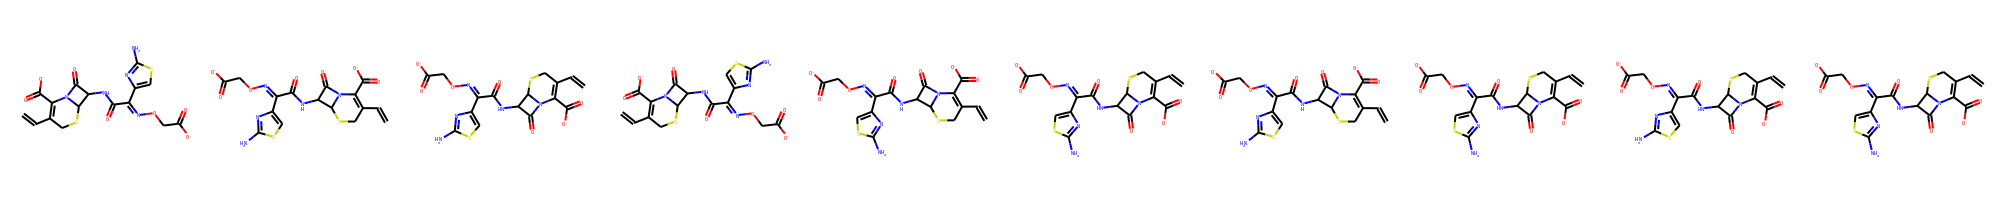

In [ ]:
ma = m
mols = []
for _ in range(10):
  smi = Chem.MolToSmiles(ma, doRandom=True)
  print(smi)
  mo = Chem.MolFromSmiles(smi)
  mols.append(mo)

Draw.MolsToGridImage(mols, molsPerRow = 10)

Check if string is invalid

In [ ]:
ms = 'c1nccc2n1ccc2'
invalid_flag=0
mo = Chem.MolFromSmiles(ms,sanitize=False)
if mo is None:
  invalid_flag=1
print('invalid_flag=',invalid_flag)

invalid_flag= 0


In [ ]:

def inchi_to_mol_file(inchi, name):
    """Converts inchi to mol, also returns mol
    
    Args:
        inchi (string): inchi to convert
        name (string): name of molecule, will be used in filename
    
    """
    
    #Read in the InChI, set the name of the molecule in memory, then create the MolBlock.
    molObj = Chem.MolFromInchi(inchi)
    molObj.SetProp("_Name",name)
    imported = Chem.MolToMolBlock(molObj)
    
    #Writes the MolBlock to a .mol file
    with open(f"../mols/{name}.mol", "w") as newfile:
        newfile.write(imported)
    
    #Also return the mol in case we want to store a variable
    return (imported)

Get the Molecular Weight

In [ ]:
mw = Descriptors.MolWt(m)
mw

451.4419999999999

Get total number of atoms

In [ ]:
m.GetNumAtoms()

43

Get properties that depend on atom-types and connectivities, such as the total polar surface area (TPSA)



In [ ]:
Chem.rdMolDescriptors.CalcTPSA(m)

190.17

Make a picture

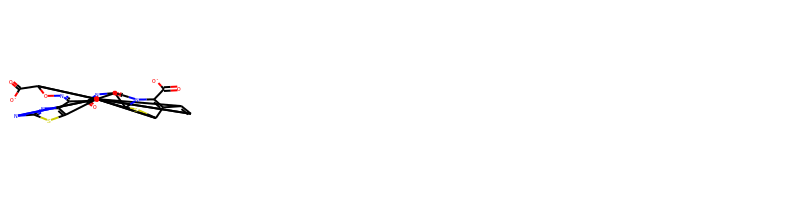

In [ ]:
img = Draw.MolsToGridImage([m],molsPerRow=4,subImgSize=(200,200))
img

Save the molecule in python format, called pickle

Query on a pattern

In [ ]:
from google.colab import drive
drive.mount('/content/mydir')

Mounted at /content/mydir


In [ ]:
# Query name of current working directory
import os
folder_name=os.getcwd()
print(folder_name)

/content


Change name of the directory where you want to save the molecules

In [ ]:
os.chdir('/content/')

In [ ]:
pickle.dump(m, open('mvic.pkl','wb'))

Save the picture img

In [ ]:
Draw.MolToFile(m,'molecule1.png')

Make a list of molecules

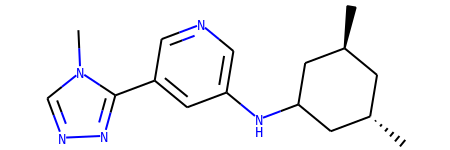

In [ ]:
mols = ['[NH3+]C(CCCNC(N)=N)C([O-])=O','C[C@@H]1CC(Nc2cncc(-c3nncn3C)c2)C[C@@H](C)C1','CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1','c1nccc2n1ccc2','Cc1c[nH]c(=O)[nH]c1=O']
ms = [Chem.MolFromSmiles(smiles) for smiles in mols]
ms[1]

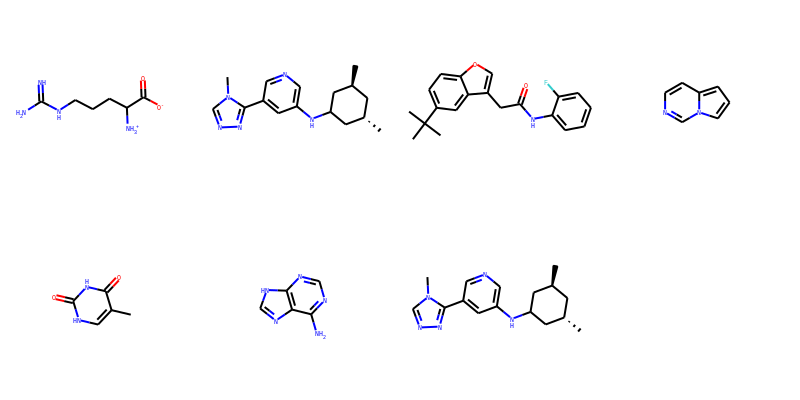

In [ ]:
m = Chem.MolFromSmiles('NC1=NC=NC2=C1N=C[NH]2')
ms.append(m)
ms.append(Chem.MolFromSmiles('C[C@@H]1CC(Nc2cncc(-c3nncn3C)c2)C[C@@H](C)C1'))
img = Draw.MolsToGridImage(ms,molsPerRow=4,subImgSize=(200,200))
img

Find Patters

In [ ]:
#pattern = Chem.MolFromSmiles('O') # Pattern of an O atom
#pattern = Chem.MolFromSmiles('CC(N)C') # Pattern of a specific sequence
pattern = Chem.MolFromSmarts('[r5]') # Pattern of 5 member ring
#pattern = Chem.MolFromSmarts('[a]')  # Pattern of aromatic ring
for mol in ms:
  print(mol.HasSubstructMatch(pattern))

False
True
True
True
False
True
True


Substitute C by Si

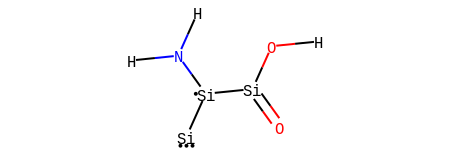

In [ ]:
mols[0]='O=C(O)C(N)C'
mols[0]=mols[0].replace('C', '[Si]')
m = Chem.MolFromSmiles(mols[0])
m = AllChem.AddHs(m)
#m = AllChem.RemoveHs(m)
m

Solubilities computed with the [Crippen RDKit module](https://www.rdkit.org/docs/source/rdkit.Chem.Crippen.html)

In [ ]:
mw=Chem.MolFromSmiles('NC1=NC=NC2=C1N=C[NH]2')
m = AllChem.AddHs(mw)
val = Crippen.MolLogP(m)
val

-0.06490000000000012

Number of rotatable bonds from the [Lipinski module](https://www.rdkit.org/docs/source/rdkit.Chem.Lipinski.html)

3


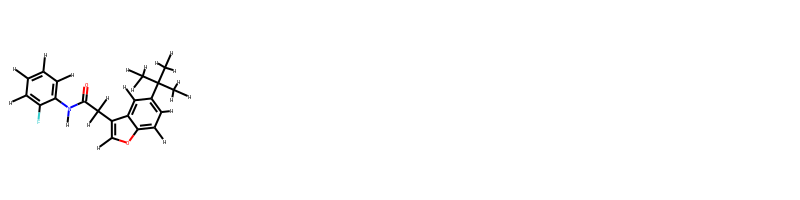

In [ ]:
me=Chem.MolFromSmiles('CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1')
m = AllChem.AddHs(me)
val = Lipinski.NumRotatableBonds(me)
print(val)
im=Draw.MolsToGridImage([m],molsPerRow=4,subImgSize=(200,200))
im

In [ ]:
val = Lipinski.NumHDonors(me)
val

1

In [ ]:
val = Lipinski.NumHeteroatoms(me)
val

4

In [ ]:
val = Lipinski.NumSaturatedHeterocycles(me)
val

0

In [ ]:
def mol_with_atom_index( mol ):
    atoms = mol.GetNumAtoms()
    for idx in range( atoms ):
        mol.GetAtomWithIdx( idx ).SetProp( 'molAtomMapNumber', str( mol.GetAtomWithIdx( idx ).GetIdx() ) )
    return mol

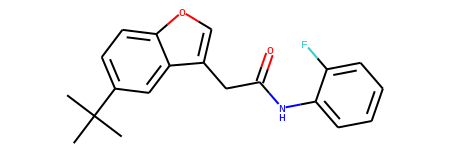

In [ ]:
me

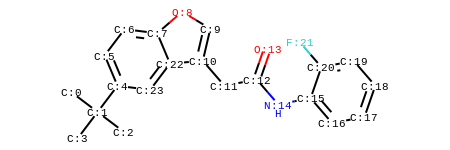

In [ ]:
mol_with_atom_index(me)

Create 100 random strings

Examples of codes using LogP from [programcreek.com](https://www.programcreek.com/python/example/120935/rdkit.Chem.Crippen.MolLogP)

In [ ]:
def check_logp(dataset):
    with open('generated_smiles_%s' % dataset, 'rb') as f:   
        all_smiles=set(pickle.load(f))
    logp_sum=0
    total=0
    logp_score_per_molecule=[]
    for smiles in all_smiles:
        new_mol=Chem.MolFromSmiles(smiles)
        try:
            val = Crippen.MolLogP(new_mol)
        except:
            continue
        logp_sum+=val
        logp_score_per_molecule.append(val)
        total+=1
    return logp_sum/total, logp_score_per_molecule 

In [ ]:
def PhyChem(smiles):
    """ Calculating the 19D physicochemical descriptors for each molecules,
    the value has been normalized with Frobenius norm.

    Arguments:
        smiles (list): list of SMILES strings.
    Returns:
        props (ndarray): m X 19 matrix as nomalized PhysChem descriptors.
            m is the No. of samples
    """
    props = []
    for smile in smiles:
#      print(smile)
      mol = Chem.MolFromSmiles(smile)
      MW = Descriptors.MolWt(mol)
      LOGP = Crippen.MolLogP(mol)
      HBA = Lipinski.NumHAcceptors(mol)
      HBD = Lipinski.NumHDonors(mol)
      rotable = Lipinski.NumRotatableBonds(mol)
      amide = AllChem.CalcNumAmideBonds(mol)
      bridge = AllChem.CalcNumBridgeheadAtoms(mol)
      heteroA = Lipinski.NumHeteroatoms(mol)
      heavy = Lipinski.HeavyAtomCount(mol)
      spiro = AllChem.CalcNumSpiroAtoms(mol)
      FCSP3 = AllChem.CalcFractionCSP3(mol)
      ring = Lipinski.RingCount(mol)
      Aliphatic = AllChem.CalcNumAliphaticRings(mol)
      aromatic = AllChem.CalcNumAromaticRings(mol)
      saturated = AllChem.CalcNumSaturatedRings(mol)
      heteroR = AllChem.CalcNumHeterocycles(mol)
      TPSA = Chem.rdMolDescriptors.CalcTPSA(mol)
      valence = Descriptors.NumValenceElectrons(mol)
      mr = Crippen.MolMR(mol)
      prop = [MW, LOGP, HBA, HBD, rotable, amide, bridge, heteroA, heavy, spiro,
                FCSP3, ring, Aliphatic, aromatic, saturated, heteroR, TPSA, valence, mr]
      props.append(prop)
    props = np.array(props)
    props = props / np.linalg.norm(props) # normalization
    return props 

In [ ]:
#pp=PhyChem([mols[0]])
pp=PhyChem(mols)
print(pp)

[[ 2.42620477e-01 -4.38470523e-03  3.64057226e-03  3.64057226e-03
   1.82028613e-03  0.00000000e+00  0.00000000e+00  1.09217168e-02
   1.09217168e-02  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   1.15260518e-01  5.82491562e-02  4.43325226e-02]
 [ 5.19500560e-01  5.66782492e-03  9.10143065e-03  1.82028613e-03
   5.46085839e-03  0.00000000e+00  0.00000000e+00  9.10143065e-03
   3.82260087e-02  0.00000000e+00  1.02391095e-03  5.46085839e-03
   1.82028613e-03  3.64057226e-03  1.82028613e-03  3.64057226e-03
   1.01262517e-01  2.03872047e-01  1.52583118e-01]
 [ 5.92290162e-01  9.19353713e-03  3.64057226e-03  1.82028613e-03
   5.46085839e-03  1.82028613e-03  0.00000000e+00  7.28114452e-03
   4.36868671e-02  0.00000000e+00  4.55071532e-04  5.46085839e-03
   0.00000000e+00  5.46085839e-03  0.00000000e+00  1.82028613e-03
   7.68888861e-02  2.25715480e-01  1.70465609e-01]
 [ 2.15046783e-01  2.42880778e-03  3.64057226e-03  0.00

In [ ]:
np.shape(pp)

(5, 19)

# [Mendeleev](https://pypi.org/project/mendeleev/0.3.1)

This package provides an API for accessing various properties of elements from the periodic table of elements, as described by the online [documentation](https://mendeleev.readthedocs.io/en/latest/) with lots of [tutorials](https://mendeleev.readthedocs.io/en/latest/tutorials.html)..

In [ ]:
!pip install mendeleev==0.3.1

     |████████████████████████████████| 180 kB 6.7 MB/s 


In [ ]:
from mendeleev import element

In [ ]:
c = element(6)

In [ ]:
c.electronegativity(scale='pauling')

2.55

In [ ]:
c.name

'Carbon'

In [ ]:
fe = element('Fe')

In [ ]:
fe.oxistates

[6, 3, 2, 0, -2]

In [ ]:
o = element(8)
o.oxistates

[-2, -1]

In [ ]:
fe.isotopes

[<Isotope(Z=26, A=54, mass=53.939609)>,
 <Isotope(Z=26, A=56, mass=55.934936)>,
 <Isotope(Z=26, A=57, mass=56.935393)>,
 <Isotope(Z=26, A=58, mass=57.933274)>]

In [ ]:
for ir in fe.ionic_radii:
  print(ir)

charge=   2, coordination=IV   , crystal_radius=77.000, ionic_radius=63.000
charge=   2, coordination=IVSQ , crystal_radius=78.000, ionic_radius=64.000
charge=   2, coordination=VI   , crystal_radius=75.000, ionic_radius=61.000
charge=   2, coordination=VI   , crystal_radius=92.000, ionic_radius=78.000
charge=   2, coordination=VIII , crystal_radius=106.000, ionic_radius=92.000
charge=   3, coordination=IV   , crystal_radius=63.000, ionic_radius=49.000
charge=   3, coordination=V    , crystal_radius=72.000, ionic_radius=58.000
charge=   3, coordination=VI   , crystal_radius=69.000, ionic_radius=55.000
charge=   3, coordination=VI   , crystal_radius=78.500, ionic_radius=64.500
charge=   3, coordination=VIII , crystal_radius=92.000, ionic_radius=78.000
charge=   4, coordination=VI   , crystal_radius=72.500, ionic_radius=58.500
charge=   6, coordination=IV   , crystal_radius=39.000, ionic_radius=25.000


# [Extended Huckel Calculations](http://rdkit.blogspot.com/2019/06/doing-extended-hueckel-calculations.html)

###**Doing extended Hueckel calculations with the RDKit**

The 2019.03 RDKit release includes an optional integration with a semi-empirical quantum mechanics package called YAeHMOP. 

If you build the RDKit yourself, this is disabled by default, but I include it when I do the RDKit conda builds.
There's no documentation for this integration yet... thus this blog post.

###**Some background**

One of my major projects in grad school was to write a software package for performing extended Hueckel calculations and analyzing and visualizing the results. I released the source for YAeHMOP ("Yet Another extended Hueckel Molecular Orbital Package") way back when using some weird license (the open-source landscape in chemistry was "a bit" different back in the mid-90s). After changing fields, I more or less forgot about YAeHMOP until a couple of years ago when Patrick Avery contacted me about integrating it into Avogadro. To make things easier, I put the source up on [Github](https://github.com/greglandrum/yaehmop) and switched to a BSD license. Since that point we've done a bit of additional cleanup work on the eHT code (the visualization pieces are still there, but really only have historic interest) and made it useable as a library.
There are a couple of applications where I think it might be interesting to have access to quick, interpretable QM results from the RDKit. These include getting partial charges and starting to think about quick and dirty descriptors for things like bond strengths and reactivity. So I decided to do an integration of YAeHMOP into the RDKit.
There are a bunch of books and papers describing extended Hueckel theory and the various types of analysis that one can do with it; I'm not going to cite all of those here. There's also no formal publication describing YAeHMOP (what a shock!), but there is a chapter in my PhD thesis that provides an fairly comprehensive tutorial overview of the theory.

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdDepictor
rdDepictor.SetPreferCoordGen(True)
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_3d = True

# this is the package including the connection to YAeHMOP
from rdkit.Chem import rdEHTTools
from rdkit.Chem import AllChem
import numpy as np

import rdkit
print(rdkit.__version__)
import time
print(time.asctime())

2020.03.5
Sun Sep 12 02:30:44 2021


In [ ]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


/usr/local/lib/python3.7/dist-packages/IPython/core/magics/pylab.py:161: UserWarning: pylab import has clobbered these variables: ['random', 'ma']
`%matplotlib` prevents importing * from pylab and numpy
  "\n`%matplotlib` prevents importing * from pylab and numpy"


Start by showing how to run an eHT calculation:

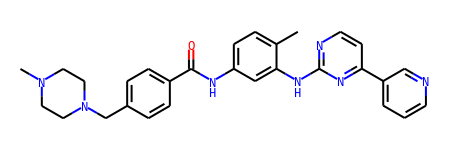

In [ ]:
# imatinib
m = Chem.MolFromSmiles('Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1')
#m = Chem.MolFromSmiles('CCCCC')

m

We need to add Hs and generate a conformation:

In [ ]:
mh = Chem.AddHs(m)
AllChem.EmbedMultipleConfs(mh,50);

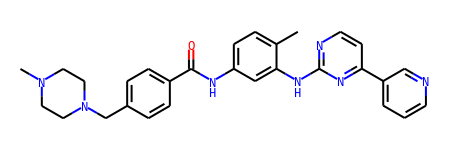

In [ ]:
m

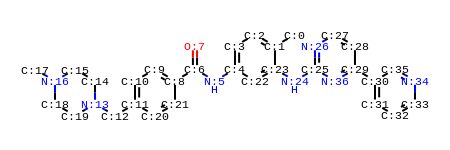

In [ ]:
mol_with_atom_index(m)

In [ ]:
passed,res = rdEHTTools.RunMol(mh,keepOverlapAndHamiltonianMatrices=True)

The first return value lets us know if the calculation succeeded:

In [ ]:
passed

True

The second contains the results of the calculation:

In [ ]:
res

In [ ]:
help(rdEHTTools)

Help on module rdkit.Chem.rdEHTTools in rdkit.Chem:

NAME
    rdkit.Chem.rdEHTTools

DESCRIPTION
    Module containing interface to the YAeHMOP extended Hueckel library.
    Please note that this interface should still be considered experimental and may
    change from one release to the next.

CLASSES
    Boost.Python.instance(builtins.object)
        EHTResults
    
    class EHTResults(Boost.Python.instance)
     |  Method resolution order:
     |      EHTResults
     |      Boost.Python.instance
     |      builtins.object
     |  
     |  Static methods defined here:
     |  
     |  GetAtomicCharges(...)
     |      GetAtomicCharges( (EHTResults)arg1) -> object :
     |          returns the calculated atomic charges
     |      
     |          C++ signature :
     |              _object* GetAtomicCharges(RDKit::EHTTools::EHTResults {lvalue})
     |  
     |  GetHamiltonian(...)
     |      GetHamiltonian( (EHTResults)arg1) -> object :
     |          returns the symmetric Hamilt

We have access to the atomic charges:

In [ ]:
res.GetAtomicCharges()

array([-5.48060774e-02, -2.56307473e-02, -5.22606141e-02, -1.33711699e-01,
        2.79027986e-01, -2.45423681e-01,  9.94157769e-01, -1.21124841e+00,
       -2.35025651e-03, -5.51644991e-03, -5.19573025e-02,  9.71653661e-02,
        2.28238079e-01, -6.17136587e-01,  2.31438900e-01,  2.24098184e-01,
       -5.59974836e-01,  1.80680583e-01,  2.31864940e-01,  2.34425224e-01,
       -6.23807557e-02,  5.65318615e-03, -1.60234909e-01,  2.74914812e-01,
       -3.41384594e-01,  9.23543422e-01, -8.59760467e-01,  4.22083942e-01,
       -1.59831455e-01,  4.98081709e-01,  6.06969744e-03,  9.91535731e-02,
       -6.67083087e-02,  3.52304866e-01, -7.95201560e-01,  3.63571495e-01,
       -9.29875824e-01,  1.57804533e-02,  1.69092822e-02,  2.65554923e-02,
        2.25809964e-02,  2.25117057e-02,  2.12445547e-01,  1.96635813e-02,
        2.13366684e-02,  2.06477512e-02, -1.82828322e-02,  7.15359812e-03,
       -2.67314985e-02, -2.29140654e-02, -1.96803671e-02,  8.34791930e-03,
        5.89500961e-03, -

In [ ]:
ham=res.GetHamiltonian()

In [ ]:
import numpy as np
from numpy import linalg as LA

In [ ]:
evalues, evectors = LA.eig(ham)

In [ ]:
np.shape(evalues)

(179,)

In [ ]:
import matplotlib.pyplot as plt

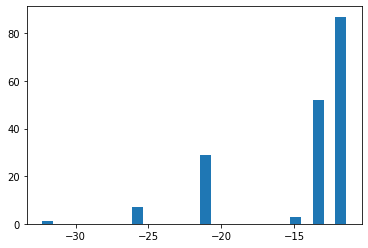

In [ ]:
_= plt.hist(evalues, bins='auto')

The reduced overlap population matrix provides the Mulliken overlap population between atoms in the molecule. It's returned as a vector representing a symmetric matrix:

In [ ]:
res.GetReducedOverlapPopulationMatrix()[:6]

array([ 2.58400121,  0.79724384,  2.79945439, -0.08816551,  1.11861689,
        2.72601599])

In [ ]:

# convenience function to set a "MulilkenOverlapPopulation" property on bonds.
def set_overlap_populations(m,ehtRes):
    rop = ehtRes.GetReducedOverlapPopulationMatrix()
    for bnd in m.GetBonds():
        a1 = bnd.GetBeginAtom()
        a2 = bnd.GetEndAtom()
        if a1.GetAtomicNum()==1:
            continue
        if a2.GetAtomicNum()==1:
            continue
        # symmetric matrix:
        i1 = max(a1.GetIdx(),a2.GetIdx())
        i2 = min(a1.GetIdx(),a2.GetIdx())
        idx = (i1*(i1+1))//2 + i2
        bnd.SetDoubleProp("MullikenOverlapPopulation",rop[idx])

In [ ]:
set_overlap_populations(mh,res)

Look at a few of the overlap populations:

In [ ]:
for bnd in list(mh.GetBonds())[:5]:
    if not bnd.HasProp("MullikenOverlapPopulation"):
        continue
    print(f'{bnd.GetIdx()} {bnd.GetBeginAtom().GetSymbol()}({bnd.GetBeginAtomIdx()})-{bnd.GetEndAtom().GetSymbol()}({bnd.GetEndAtomIdx()}) {bnd.GetBondType()} {bnd.GetDoubleProp("MullikenOverlapPopulation") :.3f}')

0 C(0)-C(1) SINGLE 0.797
1 C(1)-C(2) AROMATIC 1.119
2 C(2)-C(3) AROMATIC 1.104
3 C(3)-C(4) AROMATIC 1.066
4 C(4)-N(5) SINGLE 0.794


The wrapper also currently provides the reduced charge matrix (described in that thesis chapter linked above). I'm not going to discuss that here

###**Look at variability of charges between conformers**

The rest of this blog post is going to show a straightforward analysis one can do with the eHT results: looking at the variability of the QM charges across the different conformers.

In [ ]:
def runEHT(mh):
    """ convenience function to run an eHT calculation on all of a molecule's conformers
    
        returns a list of the results structures as well as a list of lists containing the
        charges on each atom in each conformer: chgs[atomId][confId] to use this
    """
    eres = []
    charges = [[] for x in range(mh.GetNumHeavyAtoms())]
    for cid in range(mh.GetNumConformers()):
        passed,res = rdEHTTools.RunMol(mh,confId=cid)
        eres.append(res)
        if not passed:
            raise ValueError("eHT failed")
        hvyIdx = 0
        echgs = res.GetAtomicCharges()
        for atom in mh.GetAtoms():
            if atom.GetAtomicNum()==1:
                continue
            charges[hvyIdx].append(echgs[atom.GetIdx()])
            hvyIdx+=1
    return (eres,charges)

In [ ]:
eres,charges = runEHT(mh)

Text(0, 0.5, 'partial charge')

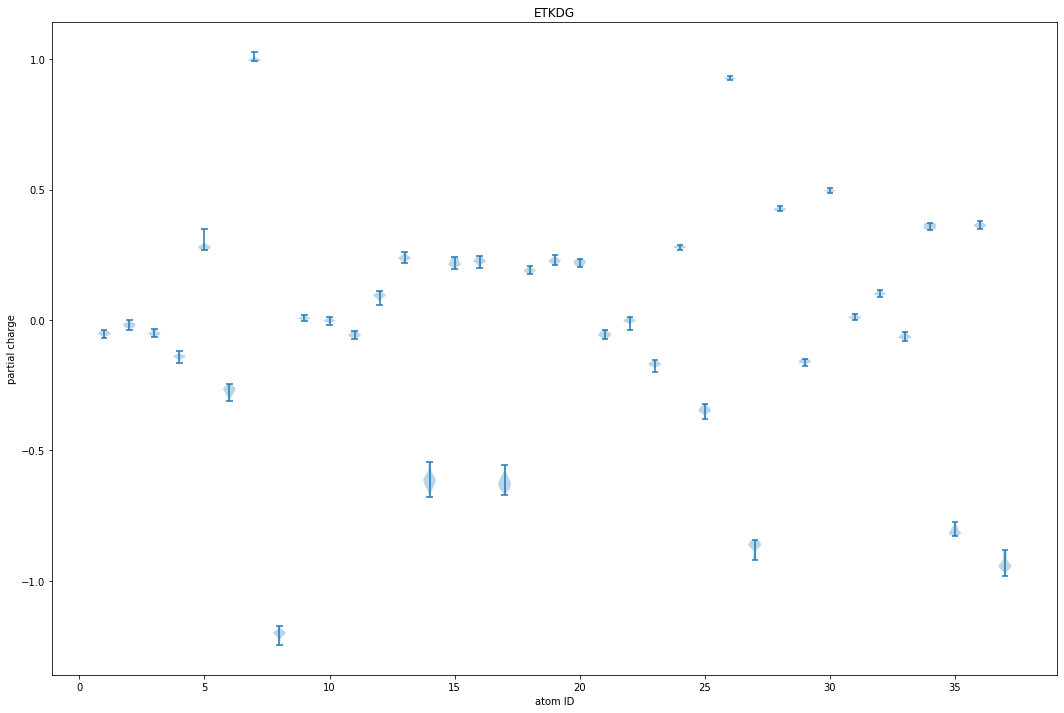

In [ ]:

figsize(18,12)
violinplot(charges);
title("ETKDG");
xlabel('atom ID');
ylabel("partial charge")

To make sense of that, draw the molecule with the atoms numbered:

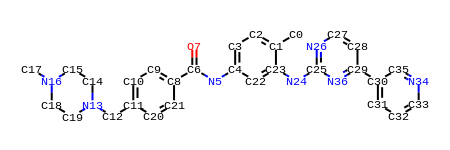

In [ ]:
for at in m.GetAtoms():
    at.SetProp("atomLabel",f'{at.GetSymbol()}{at.GetIdx()}')
m


Look at the results for a couple of the atoms that show the most variability

In [ ]:
tchgs = sorted((y,x) for x,y in enumerate(charges[13]))
tchgs[:2],tchgs[-2:]

([(-0.6782180001525204, 22), (-0.6582349074524072, 42)],
 [(-0.5470327461480444, 35), (-0.5450527229170963, 33)])

In [ ]:
tchgs = sorted((y,x) for x,y in enumerate(charges[16]))
tchgs[:2],tchgs[-2:]

([(-0.6711709548473772, 9), (-0.6550157380622115, 17)],
 [(-0.5599748361611359, 0), (-0.5576327171737734, 41)])

In [ ]:
!pip install py3Dmol

  Using cached py3Dmol-1.7.0-py2.py3-none-any.whl (6.3 kB)


You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

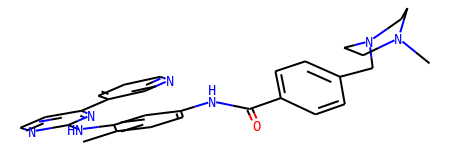

In [ ]:
tm1 = Chem.MolFromMolBlock(Chem.MolToMolBlock(mh,confId=1))
tm1

In [ ]:
import sys
sys.path.append('/usr/local/lib/python3.7/site-packages/')
import rdkit
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole

You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

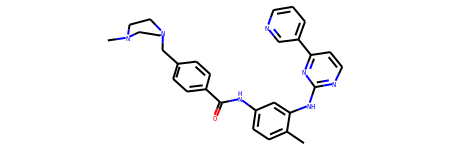

In [ ]:
tm24 = Chem.MolFromMolBlock(Chem.MolToMolBlock(mh,confId=24))
tm24


The difference here is the conformation of the piperazine ring. In the first case (more negative N), the ring is in the chair form. In the second (less negative N), it's in the boat form.

In [ ]:
tchgs = sorted((y,x) for x,y in enumerate(charges[36]))
tchgs[:2],tchgs[-2:]

([(-0.9826149001244697, 25), (-0.9658580023107946, 37)],
 [(-0.8894816788697923, 10), (-0.8825592742046382, 20)])

In [ ]:
tchgs = sorted((y,x) for x,y in enumerate(charges[26]))
tchgs[:2],tchgs[-2:]

([(-0.9193607951599598, 20), (-0.9170184623592799, 10)],
 [(-0.8447998085245916, 28), (-0.8438110974729329, 32)])

You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

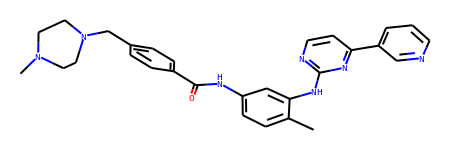

In [ ]:
tm5 = Chem.MolFromMolBlock(Chem.MolToMolBlock(mh,confId=5))
tm5

You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

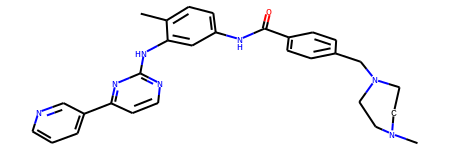

In [ ]:
tm2 = Chem.MolFromMolBlock(Chem.MolToMolBlock(mh,confId=2))
tm2

The difference here is the orientation of the two Ns in the pyrimidine ring relative to the H on the exocyclic amine (atom 24). The N that is closer to the H has a more negative charge than the other.

What if we do an MMFF minimization of each conformer?

In [ ]:
mh_mmff = Chem.Mol(mh)
optRes = AllChem.MMFFOptimizeMoleculeConfs(mh_mmff,maxIters=500)
for i,needsMore in enumerate(optRes):
    while needsMore:
        needsMore = AllChem.MMFFOptimizeMolecule(mh_mmff,maxIters=500,confId=i)

In [ ]:
eres,mmff_charges = runEHT(mh_mmff)

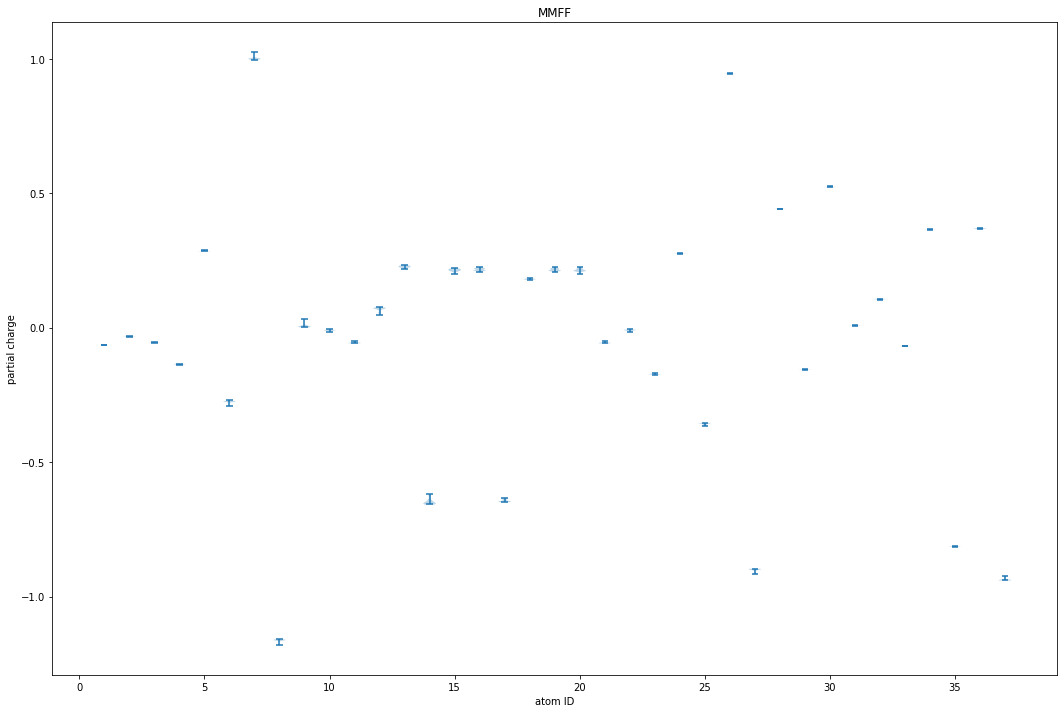

In [ ]:
figsize(18,12)
violinplot(mmff_charges);
title("MMFF");
xlabel('atom ID');
ylabel("partial charge");


Are the MMFF conformers actually different from each other?

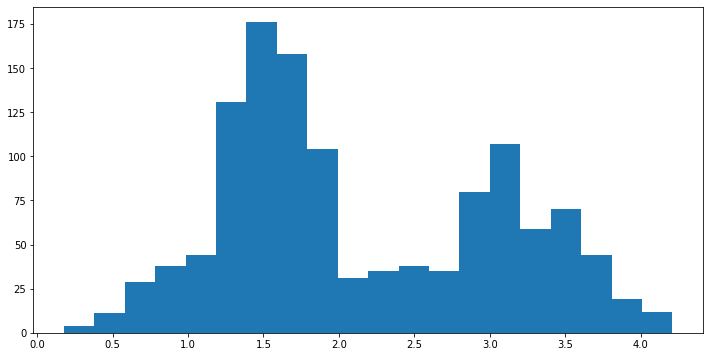

In [ ]:
rmsds = []
cp1 = Chem.RemoveHs(mh_mmff)
cp2 = Chem.RemoveHs(mh_mmff)
for i in range(mh_mmff.GetNumConformers()):
    for j in range(i+1,mh_mmff.GetNumConformers()):
        rmsds.append(AllChem.GetBestRMS(cp1,cp2,prbId=i,refId=j))
figsize(12,6)
hist(rmsds,bins=20);

The inter-conformer charge differences we saw before have vanished, are the structural features still different?

You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

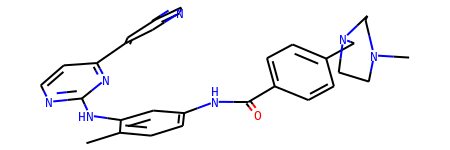

In [ ]:
tm1 = Chem.MolFromMolBlock(Chem.MolToMolBlock(mh_mmff,confId=1))
tm1

You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

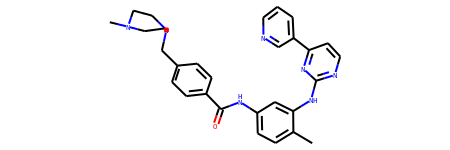

In [ ]:
tm24 = Chem.MolFromMolBlock(Chem.MolToMolBlock(mh_mmff,confId=24))
tm24

Nope, both piperazine rings are now chair. That explains the charges being more or less constant

You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

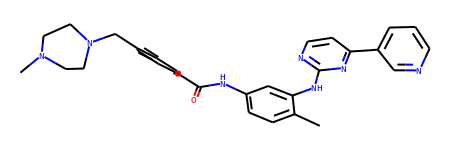

In [ ]:
tm5 = Chem.MolFromMolBlock(Chem.MolToMolBlock(mh_mmff,confId=5))
tm5

You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

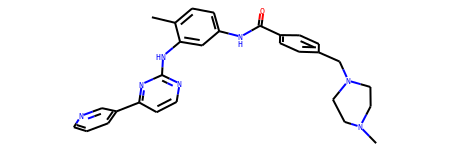

In [ ]:
tm2 = Chem.MolFromMolBlock(Chem.MolToMolBlock(mh_mmff,confId=2))
tm2

Here the difference in the conformations is still present; the charge differences are just much smaller than previously

What about differences in charges between the conformation generation methods?

In [ ]:
charge_compare = []
for i in range(len(charges)):
    both = list(zip(charges[i],mmff_charges[i]))
    charge_compare.extend(both)

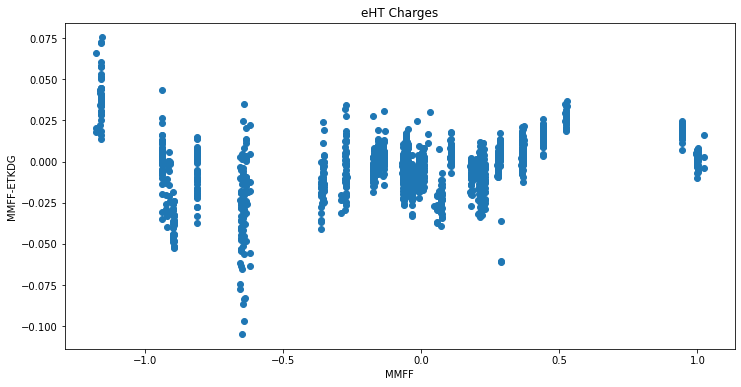

In [ ]:
scatter([y for x,y in charge_compare],[y-x for x,y in charge_compare])
xlabel('MMFF')
ylabel('MMFF-ETKDG');
title('eHT Charges');

There are differences, but they are mostly reasonably small.